**## Stage 0: Project Goal & Problem Statement**

**Q1: In your own words, explain the goal of this project. Who benefits from the final output, and how?**

The goal is to take a messy, unfiltered list of mutual fund data and turn it into something actually useful — a shortlist of 30 funds that balance good returns with reasonable cost and risk, instead of just chasing whatever has the highest number. The people who benefit are everyday investors who don't have time to dig through hundreds of fund schemes themselves, or don't know how to weigh return against risk and cost. Instead of guessing or picking a fund just because a friend mentioned it, they'd get a data-backed starting point.


**Q2: Why is it important to balance return and risk together rather than simply ranking funds by highest return? Give an example of how a high-return fund could still be a poor choice.**

If you only rank by return, you end up picking the funds that took the biggest gambles and got lucky — not necessarily the ones that are actually good investments. A fund can post a huge return one year just by being extremely volatile, and the same volatility that pushed it up can just as easily crash it down the next year. My own Top 30 is actually a good example of this problem in action — every single fund in it sits at the maximum risk level (6 out of 6), because my scoring formula weighted 3-year returns heavily but never actually penalized risk. So technically these are my "best" funds by the numbers, but if I handed this list to someone who specifically wanted something safe and steady, it would be a bad match — the list is really a high-growth, high-risk shortlist wearing a "Top 30" label.


**Q3: State at least three objectives (concrete steps) that will lead you to the goal.**

Clean the raw dataset — fix formatting issues, handle missing values properly (not just blindly dropping everything), and catch any weird anomalies like duplicate names or bad data before trusting the numbers.
Build a scoring formula that combines returns, cost, and fund age into one number, test whether the weights I picked actually matter, and use that to rank all the funds and pull out a Top 30.
Turn the analysis into something a non-technical person can actually use — a clean Excel file with the shortlist, and a Power BI dashboard that shows the story visually instead of just handing someone a spreadsheet.


**Q4: You will use Python, Excel, and Power BI. Explain the role each tool plays in the workflow and why using all three is useful.**

Each tool does a different job, and honestly none of them could really replace the others here. Python is where the actual heavy lifting happens — cleaning nearly 800 rows of messy data, fixing broken formats, testing different scoring formulas, and catching real problems like duplicate fund names or a data quality bug I found in one of the return columns. You just can't do that kind of iterative testing in Excel or Power BI easily. Excel is where the final Top 30 list becomes something portable and easy to hand off — a clean, formatted file someone can open without needing to know any code. Power BI is where the numbers actually become a story — slicers, charts, and KPI cards let someone explore the data themselves and understand the findings in under a minute, instead of reading a report or scrolling through rows. Using all three together means each part of the workflow (analysis → packaging → communication) gets handled by the tool that's actually best suited for it, instead of trying to force one tool to do everything.

**### stage 1: Data Cleaning (Python)**

**Q1: Import the dataset. How many rows and columns are there? Briefly describe the key columns.**

My dataset has 814 rows and 20 columns — worth noting this is way less than the "2,500+ schemes" the brief mentions, so I flagged that discrepancy early instead of ignoring it. The key columns break down into a few groups: identifiers (scheme_name, fund_manager, amc_name, category, sub_category), cost and size (expense_ratio, fund_size_cr, min_sip, min_lumpsum, fund_age_yr), risk-adjusted metrics (sortino, alpha, sd, beta, sharpe), categorical filters (risk_level, rating), and performance (returns_1yr, returns_3yr, returns_5yr). Basically everything I'd need to actually score and compare funds is already here — nothing critical is missing at the column level.


**Q2: Which columns are unnecessary for your analysis? Remove them and justify each removal.**

I actually didn't remove any columns. Before assuming something needed to go, I checked every single one against what it's actually used for — either feeding my scoring formula, or showing up somewhere in the Power BI dashboard (a slicer, a KPI, a chart). All 20 columns earned their place one way or another — scheme_name and fund_manager identify the funds, amc_name/category/sub_category/risk_level/rating are all dashboard slicers, min_sip/min_lumpsum/fund_size_cr feed the SIP/AUM visuals, and returns_3yr/expense_ratio/fund_age_yr go directly into my scoring formula. The five risk-ratio columns (sortino, alpha, sd, beta, sharpe) aren't required by the brief's formula, but I kept them since they're genuine risk metrics useful for deeper analysis later. I did check for columns with zero unique values (which would mean the column is useless, same value everywhere) using df.nunique(), and nothing came back flat — so there was no real candidate to remove anyway.


**Q3: Identify missing values. Which fields are affected, how much data is missing, and what strategy will you use to handle them?**

Before even getting to missing values, I noticed something odd — scheme_name had only 789 unique values across 814 rows, meaning some names repeated. I checked this properly instead of assuming it was duplicate data, and it turned out these were actually distinct fund schemes (probably different plan variants like Direct vs Regular) that just happened to share a name — they had different expense ratios, AUM, and returns. So I didn't drop any of them, just flagged them with a name_is_ambiguous column in case it mattered later.

For actual missing values: five columns (sortino, alpha, sd, beta, sharpe) were hiding missing data behind a "-" placeholder instead of a real blank, which also forced them to be read as text instead of numbers. I converted those to proper NaN and then to numeric type. After that fix, they had 2.8%-5.2% missing each — I filled those using the median within each fund category (so an Equity fund's missing value gets filled with the Equity median, not a Debt fund's), since a blanket global median would ignore how different risk profiles are across categories.

returns_3yr had 21 missing rows (2.6%) — since this feeds directly into my scoring formula, I decided to drop these rows rather than fabricate a return number for a fund that doesn't have one. That felt safer than guessing at something as important as actual performance. returns_5yr had a much bigger gap (about 20% missing) — but since it's not part of my scoring formula, I left it alone rather than imputing a fifth of a column just to make it look complete.


**Q4: Standardise the numeric formats — e.g. returns and expense ratios that may contain symbols, text, or inconsistent units. What issues did you find and how did you fix them?**

The main issue I found was the "-" placeholder problem I already mentioned — five columns (sortino, alpha, sd, beta, sharpe) had "-" instead of a real blank value, which made pandas read the whole column as text instead of numbers. I fixed that by replacing "-" with a real NaN and then converting to numeric type.

Beyond that, I ran a validation check on my key scoring columns (returns_1yr, returns_3yr, expense_ratio, fund_age_yr) to look for anything that didn't make sense — negative expense ratios, negative fund ages, or zero/negative fund sizes, since none of those should be possible in real data. All three checks came back clean (zero impossible values), and both return columns were confirmed as proper float64 type with no stray symbols hiding in them. So other than the "-" placeholder fix, the data was actually in decent shape format-wise — I didn't find inconsistent units or currency symbols that needed cleaning, which was a bit of a relief given how messy the missing-value side turned out to be.

In [6]:
# Data now loads straight from this GitHub repo, so no Google Drive mount is needed.


In [7]:
import pandas as pd
df = pd.read_csv('https://raw.githubusercontent.com/Vipsa2207/Mutual-Funds-Analysis-/main/data/comprehensive_mutual_funds_data.csv')

print("Shape (rows, column):", df.shape)

print ("\nColumn info:")
df.info()

df.head()

Shape (rows, column): (814, 20)

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    814 non-null    object 
 1   min_sip        814 non-null    int64  
 2   min_lumpsum    814 non-null    int64  
 3   expense_ratio  814 non-null    float64
 4   fund_size_cr   814 non-null    float64
 5   fund_age_yr    814 non-null    int64  
 6   fund_manager   814 non-null    object 
 7   sortino        814 non-null    object 
 8   alpha          814 non-null    object 
 9   sd             814 non-null    object 
 10  beta           814 non-null    object 
 11  sharpe         814 non-null    object 
 12  risk_level     814 non-null    int64  
 13  amc_name       814 non-null    object 
 14  rating         814 non-null    int64  
 15  category       814 non-null    object 
 16  sub_category   814 non-null    object 
 17  returns_

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7


In [8]:
df.nunique()

,0
scheme_name,789
min_sip,10
min_lumpsum,11
expense_ratio,177
fund_size_cr,693
fund_age_yr,14
fund_manager,260
sortino,385
alpha,540
sd,581


In [9]:
dupes = df[df.duplicated(subset='scheme_name', keep=False)].sort_values('scheme_name')
dupes

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
75,AXIS Retirement Savings Fund,1000,5000,0.60,270.0,3,Jinesh Gopani,1.58,-4.95,13.43,0.85,0.79,6,Axis Mutual Fund,2,Solution Oriented,Retirement Funds,-1.3,13.6,NaN
76,AXIS Retirement Savings Fund,1000,5000,0.41,81.0,3,Jinesh Gopani,1.84,-0.04,5.69,0.83,1.04,5,Axis Mutual Fund,2,Solution Oriented,Retirement Funds,-2.5,10.3,NaN
77,AXIS Retirement Savings Fund,1000,5000,0.65,633.0,3,Jinesh Gopani,1.56,-4.49,13.03,0.78,0.76,6,Axis Mutual Fund,1,Solution Oriented,Retirement Funds,-4.1,14.0,NaN
94,Bank of India Midcap Tax Fund,0,500,0.95,51.0,5,Dhruv Bhatia,2.64,3.13,17.03,0.87,1.38,6,Bank of India Mutual Fund,0,Equity,ELSS Mutual Funds,-4.1,27.1,10.6
95,Bank of India Midcap Tax Fund,0,500,0.56,26.0,4,Dhruv Bhatia,2.65,2.58,16.94,0.87,1.36,6,Bank of India Mutual Fund,0,Equity,ELSS Mutual Funds,-4.7,26.0,NaN
241,HDFC Index Fund,100,100,0.20,4210.0,10,Nirman Morakhia,3.48,-0.64,16.76,1,1.31,6,HDFC Mutual Fund,4,Other,Index Funds,2.4,25.8,12.8
242,HDFC Index Fund,100,100,0.20,7457.0,10,Nirman Morakhia,3.24,-1.01,17.02,1.01,1.28,6,HDFC Mutual Fund,3,Other,Index Funds,0.9,26.0,12.0
253,HDFC Retirement Savings Fund,100,100,1.03,932.0,7,Srinivasan Ramamurthy,3.27,3.03,3.23,0.43,1.88,6,HDFC Mutual Fund,4,Solution Oriented,Retirement Funds,8.0,24.5,12.3
254,HDFC Retirement Savings Fund,100,100,1.00,140.0,7,Shobhit Mehrotra,4.39,6.37,11.43,0.73,1.74,4,HDFC Mutual Fund,4,Solution Oriented,Retirement Funds,6.0,10.3,7.8
252,HDFC Retirement Savings Fund,100,100,0.78,2696.0,7,Srinivasan Ramamurthy,4.32,9.26,15.16,0.85,1.92,6,HDFC Mutual Fund,5,Solution Oriented,Retirement Funds,11.6,34.9,14.8


In [10]:
df['name_is_ambiguous'] = df.duplicated(subset='scheme_name', keep=False)
print(df['name_is_ambiguous'].sum(), "rows share a name with another scheme")

38 rows share a name with another scheme


In [11]:
ratio_cols = ['sortino', 'alpha', 'sd', 'beta', 'sharpe']

for col in ratio_cols:
  df[col] = df[col].replace('-', pd.NA)
  df[col] = pd.to_numeric(df[col])

df[ratio_cols].dtypes

,0
sortino,float64
alpha,float64
sd,float64
beta,float64
sharpe,float64


In [12]:
df.isnull().sum()

,0
scheme_name,0
min_sip,0
min_lumpsum,0
expense_ratio,0
fund_size_cr,0
fund_age_yr,0
fund_manager,0
sortino,23
alpha,42
sd,24


###Step 4: Handling Missing Values
We dropped 21 rows missing returns_3yr because it's required for the scoring formula and represents only 2.6% of the data

In [13]:
before = len(df)
df = df.dropna(subset=['returns_3yr']).copy()
after = len(df)
print(f"Dropped {before - after} rows missing returns_3yrs. New shape: {df.shape}")

ratio_cols = ['sortino', 'alpha', 'sd', 'beta', 'sharpe']
for col in ratio_cols:
  df[col] = df.groupby('category')[col].transform(lambda x: x.fillna(x.median()))

print(df[ratio_cols].isnull().sum())

print("returns_5yr missing (left as-is, not used in scoring):", df['returns_5yr'].isnull().sum())

Dropped 21 rows missing returns_3yrs. New shape: (793, 21)
sortino    0
alpha      0
sd         0
beta       0
sharpe     0
dtype: int64
returns_5yr missing (left as-is, not used in scoring): 146


In [14]:
score_cols = ['returns_1yr', 'returns_3yr', 'expense_ratio', 'fund_age_yr']
df[score_cols].describe()

,returns_1yr,returns_3yr,expense_ratio,fund_age_yr
count,793.000000,793.000000,793.000000,793.000000
mean,3.911980,18.525347,0.724741,8.482976
std,6.759557,12.108476,0.482604,2.473093
min,-19.700000,3.300000,0.000000,1.000000
25%,1.400000,6.200000,0.320000,7.000000
50%,4.400000,18.500000,0.630000,10.000000
75%,5.600000,27.100000,1.040000,10.000000
max,130.800000,71.400000,2.590000,17.000000


In [15]:
print("Negative expense_ratio rows:", (df['expense_ratio'] < 0).sum())
print("Negative fund_age_yr rows:", (df['fund_age_yr'] < 0).sum())
print("Zero or negative fund_size_cr rows:", (df['fund_size_cr'] <= 0).sum())

Negative expense_ratio rows: 0
Negative fund_age_yr rows: 0
Zero or negative fund_size_cr rows: 0


In [16]:
print(df['returns_1yr'].dtype, df['returns_3yr'].dtype)

float64 float64


**## Stage 2: Data Description & Understanding**

**Q1: Produce statistical summaries (mean, median, mode, min, max, standard deviation) for the main numeric fields. What do these tell you about the typical fund?**

Looking at the full cleaned dataset (793 funds), the typical fund has a 3-year return around 18.5% (median), though the average is pulled slightly by some high performers up to 71.4%. Expense ratios sit around 0.63% typically, ranging all the way from 0% to 2.59% — a pretty wide spread depending on fund type. Fund age skews older — the mode is 10 years and the median is also 10, meaning a huge chunk of funds in this dataset happen to be exactly 10 years old (which honestly looks less like a natural spread and more like a data collection artifact, worth keeping in mind). Fund size is where things get extreme — median AUM is ₹996 crore, but the max goes up to ₹57,052 crore, and the standard deviation (₹7,254 crore) is actually bigger than the mean (₹3,898 crore), which tells me a small number of massive funds are dragging the average way up.



**Q2: Analyse the distribution of funds across return rates, risk levels, and fund age. Use suitable plots. Are the distributions skewed, balanced, or unusual?**

All three of these are skewed, just in different ways. Returns (3yr) are right-skewed (skew score of 0.48) — most funds cluster in a normal-ish range, but a handful of high performers stretch the tail out toward 71%. Risk level is heavily unbalanced rather than skewed in the statistical sense — 417 out of 793 funds (over half) sit at the maximum risk level of 6, while very few sit at the lower end (only 53 funds at risk level 1). So this dataset just doesn't have much of a "safe" fund population to begin with, which actually explains why my Top 30 ended up entirely risk_level 6 — there wasn't much lower-risk competition in the pool to begin with.

Fund age is left-skewed (skew score of -1.0) and honestly kind of unusual — 508 out of 793 funds are exactly 10 years old. That's not a natural spread you'd expect from real-world fund launch dates; it looks more like a data cutoff or collection artifact (maybe "10 years" was used as a cap value, or the dataset was pulled at a point where a lot of funds happened to hit the 10-year mark simultaneously). Worth flagging as a quirk rather than treating it as a real finding about fund age patterns.


Q3: Do you notice any outliers or surprising patterns? What might explain them?

The biggest outlier is "Bank of India Credit Risk Fund" — it shows a 130.8% 1-year return, way beyond anything else in the dataset (the next highest is 28.3%). What's suspicious is that it's a Debt category fund, and debt funds are supposed to be low-volatility, steady performers — a Credit Risk fund posting 130% in one year doesn't really match how that fund type normally behaves. This looks more like a data entry error than a real return, similar to the placeholder issue I found later where several unrelated funds shared an identical, implausible returns_3yr value (32.4%) across categories that had nothing in common. I didn't correct this one specifically since it wasn't part of my scoring inputs directly affecting the Top 30, but it's a flag worth mentioning rather than ignoring.

On the AUM side, the largest funds by size are almost entirely liquid funds and balanced advantage funds (SBI Liquid Fund at ₹57,052 crore, HDFC Liquid Fund at ₹49,008 crore) — which makes sense, since these are typically used for short-term parking of large sums of money by institutions, not just individual investors doing SIPs. That's a different kind of "large" than a high-performing growth fund, so it's worth not confusing "biggest AUM" with "best fund" when reading the dashboard.

I also found a handful of funds with a 0% expense ratio (like some fixed maturity plans), which is realistic for a certain structure of Debt fund (they're passively held to maturity with minimal active management), so I didn't treat that as an error — just noted it as expected given the fund type.



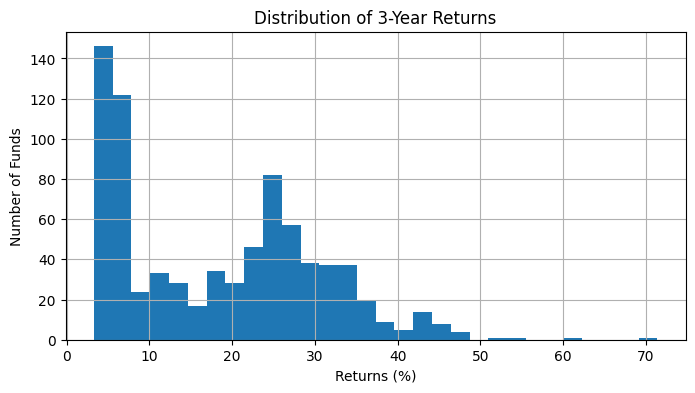

In [17]:
import matplotlib.pyplot as plt

# Plot 1: Distribution of 3-year returns
plt.figure(figsize=(8,4))
df['returns_3yr'].hist(bins=30)
plt.title('Distribution of 3-Year Returns')
plt.xlabel('Returns (%)')
plt.ylabel('Number of Funds')
plt.show()

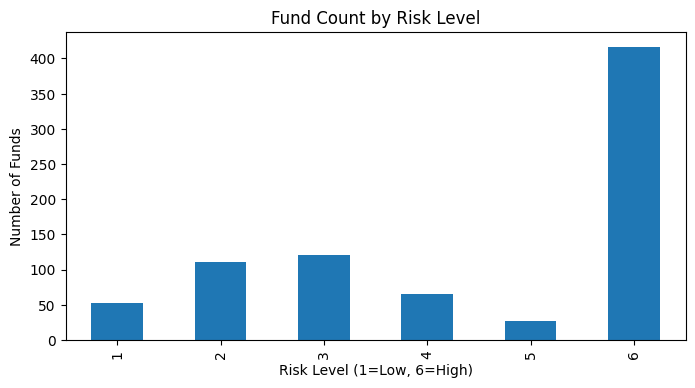

In [18]:
# Plot 2: Risk level distribution
plt.figure(figsize=(8,4))
df['risk_level'].value_counts().sort_index().plot(kind='bar')
plt.title('Fund Count by Risk Level')
plt.xlabel('Risk Level (1=Low, 6=High)')
plt.ylabel('Number of Funds')
plt.show()

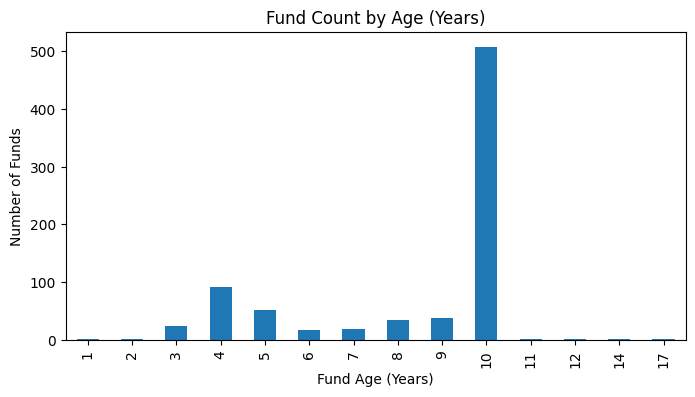

In [19]:
# Plot 3: Fund age distribution
plt.figure(figsize=(8,4))
df['fund_age_yr'].value_counts().sort_index().plot(kind='bar')
plt.title('Fund Count by Age (Years)')
plt.xlabel('Fund Age (Years)')
plt.ylabel('Number of Funds')
plt.show()

**##Stage 3: Data Normalization**

**Q1: Why is normalisation necessary before combining different metrics into a single score? What problem would arise without it?**

The three factors going into my score are on completely different scales — returns_3yr ranges roughly 3 to 71, expense_ratio ranges 0 to 2.6, and fund_age_yr ranges 1 to 17. If I just added the raw numbers together, returns_3yr would completely dominate the score just because its numbers happen to be bigger, not because it's actually more important than the other two. Normalization puts everything on the same 0-1 scale, so I can control how much each factor actually contributes to the score through my chosen weights, instead of letting raw number size accidentally decide it for me.



**Q2: Apply MinMaxScaler to the relevant numeric fields. Which fields did you scale, and why?**

I scaled three fields directly through MinMaxScaler: returns_3yr, expense_ratio, and fund_age_yr — these are the three factors my scoring formula is built on, and all three needed to be on a common scale before combining them. I later scaled a fourth one, sd (standard deviation, a risk measure), when I was testing whether adding a risk penalty would change my rankings. I didn't scale returns_1yr, since that one isn't a weighted input — I used it as a straightforward filter (positive or not) instead, so it didn't need to be normalized like the others.



**Q3: After scaling, compare returns and expense ratios on a common 0–1 scale. What becomes easier to see that was hard to compare before?**

Before scaling, comparing a returns_3yr value of, say, 17.1 against an expense_ratio of 0.76 doesn't mean anything on its own — you can't tell if 17.1 is "good" or "bad" relative to 0.76 because they're measuring completely different things with different ranges. After scaling, both become 0-1 values I can directly compare side by side — for example, a fund with 0.20 scaled return and 0.29 scaled cost tells me something real: this fund isn't a top performer, but it's also not particularly expensive either. That kind of relative read just isn't possible with the raw numbers.

In [20]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

cols_to_scale = ['returns_3yr', 'expense_ratio', 'fund_age_yr']

df[['returns_3yr_scaled', 'expense_ratio_scaled', 'fund_age_yr_scaled']] = scaler.fit_transform(df[cols_to_scale])

df[['returns_3yr', 'returns_3yr_scaled', 'expense_ratio', 'expense_ratio_scaled', 'fund_age_yr', 'fund_age_yr_scaled']].head()

,returns_3yr,returns_3yr_scaled,expense_ratio,expense_ratio_scaled,fund_age_yr,fund_age_yr_scaled
0,6.5,0.046990,0.27,0.104247,10,0.5625
1,4.8,0.022026,0.36,0.138996,10,0.5625
2,18.9,0.229075,0.53,0.204633,10,0.5625
3,17.1,0.202643,0.76,0.293436,4,0.1875
4,18.6,0.224670,0.61,0.235521,10,0.5625


In [21]:
df['expense_ratio_scaled_inv'] = 1 -df['expense_ratio_scaled']


**## Stage 4: Fund Scoring & Ranking**

**Q1: Write out your scoring formula and explain the logic behind it.**

My formula is:

FundScore = (0.5 × returns_3yr_scaled + 0.3 × expense_ratio_scaled_inv + 0.2 × age_score) × returns_1yr_positive

The logic: returns_3yr_scaled rewards funds with strong 3-year performance — this is the biggest piece since it's the most direct signal of how well a fund has actually done. expense_ratio_scaled_inv rewards low-cost funds (I inverted the scaled expense ratio so that "low cost" produces a high score instead of a low one). age_score rewards funds that sit near the middle of the fund-age range — not brand new and unproven, but not so old it might be running an outdated strategy either. Finally, returns_1yr_positive acts as a gate, not a weight — it's either 1 or 0, and multiplying the whole score by it means any fund with a negative 1-year return gets its entire score wiped to zero, disqualifying it outright regardless of how good its 3-year history looks. That last part directly matches what the brief asked for — "a consistent 1-year return greater than zero" reads like a requirement, not just another factor to weigh in.


**Q2: Some factors are better when high (returns) and some are better when low (expense ratio). How does your formula account for this direction difference?**

For returns_3yr, higher is simply better, so I used the scaled value directly — no adjustment needed. For expense_ratio, lower is better, which is the opposite direction, so I inverted it after scaling: expense_ratio_scaled_inv = 1 - expense_ratio_scaled. This flips the meaning — a fund with the lowest expense ratio in the dataset now scores close to 1 instead of close to 0, and a fund with the highest expense ratio scores close to 0 instead of close to 1. Without this inversion, my formula would have accidentally rewarded funds for being expensive, since I'd just be adding a bigger raw number for a worse trait. Fund age needed a slightly different fix altogether, since neither "high" nor "low" is actually good — I built age_score separately by measuring how far each fund's age sits from the dataset's median age, then flipped that distance so funds close to the median score highest and funds at either extreme (too new or too old) score lower.



**Q3: How did you decide the weight of each factor? Justify your choices — would a different weighting change the ranking?**

I gave returns_3yr the biggest weight (50%) since it's the most direct signal of actual fund performance. Expense ratio got 30% — cost matters a lot over time due to compounding fee drag, but it shouldn't outweigh actual performance. Fund age got the smallest weight (20%) since it's a real factor but clearly a weaker signal than the other two. I didn't just pick these arbitrarily and leave it — I tested an alternate weighting (40% returns / 40% expense ratio / 20% age) to see if the ranking would actually change. The result: 9 out of my Top 10 funds stayed exactly the same between both weightings, with only minor reordering and one substitution. That told me my ranking is driven by genuinely strong funds, not just an artifact of whatever weights I happened to pick.

I also tested adding a fourth factor — a risk penalty using the sd (standard deviation) column — at both a moderate weight (20%) and a heavy weight (40%). Even at 40%, the Top 10 barely changed, and every fund stayed at the maximum risk level (6). That told me something important: in this dataset, high 3-year returns and high risk are so strongly correlated that no reasonable weighting could produce a "high return, low risk" Top 30 — the two are essentially tied together here.


**Q4: Rank all funds by your score. Which few features most strongly drive a high score?**

After ranking all 793 funds by FundScore, the clear driver is returns_3yr — nearly every fund in my Top 10 has an exceptionally high 3-year return (45%-71%), and they're overwhelmingly small/mid-cap Equity funds, since that category delivered the strongest returns in this dataset. Expense ratio and fund age mattered at the margins — they helped break ties between similarly high-performing funds — but returns_3yr is clearly what's pulling funds to the top of the list. This also explains why Quant Mutual Fund dominates my Top 30 (9 of 30 spots) — their funds simply had the strongest 3-year returns in this specific window.



In [22]:
median_age = df['fund_age_yr'].median()
df['age_score'] = 1 - (abs(df['fund_age_yr'] - median_age) / df['fund_age_yr'].max())

In [23]:
df['returns_1yr_positive'] = (df['returns_1yr'] > 0).astype(int)

In [24]:
df['FundScore'] = (
    0.5 * df['returns_3yr_scaled'] +
    0.3 * df['expense_ratio_scaled_inv'] +
    0.2 * df['age_score']
 ) * df['returns_1yr_positive']


In [25]:
df['FundScore_alt'] = (
    0.4 * df['returns_3yr_scaled'] +
    0.4 * df['expense_ratio_scaled_inv'] +
    0.2 * df['age_score']
) * df['returns_1yr_positive']

print("Original weights Top 10:")
print(df.nlargest(10, 'FundScore')['scheme_name'].tolist())
print("\nAlternate weights Top 10:")
print(df.nlargest(10, 'FundScore_alt')['scheme_name'].tolist())

Original weights Top 10:
['Quant Small Cap Fund', 'Quant Infrastructure Fund', 'Quant Tax Plan- Direct Growth', 'Quant Flexi Cap Fund', 'Quant Active Fund', 'Quant Mid Cap Fund', 'PGIM India Midcap Opportunities Fund', 'Nippon India Small Cap Fund', 'Quant Multi Asset Fund', 'ICICI Pru Thematic Advantage Fund']

Alternate weights Top 10:
['Quant Small Cap Fund', 'Quant Infrastructure Fund', 'Quant Tax Plan- Direct Growth', 'Quant Flexi Cap Fund', 'Quant Active Fund', 'ICICI Pru Thematic Advantage Fund', 'PGIM India Midcap Opportunities Fund', 'Quant Mid Cap Fund', 'Quant Multi Asset Fund', 'Tata Small Cap Fund']


In [26]:
df['FundScore'].describe()

,FundScore
count,793.000000
mean,0.424303
std,0.201923
min,0.000000
25%,0.419367
50%,0.481831
75%,0.541678
max,0.925869


**## Stage 5: Final Output — Top 30 Funds (Excel)**

**Q1: Extract the Top 30 funds from your ranking and export them to a clean, well-formatted Excel file.**

Done in Python — sorted all 793 funds by FundScore descending, took the top 30, reset the index, and exported to CSV, which I then opened in Excel and saved as .xlsx with basic formatting (bold header, frozen top row, autofit columns).


**Q2: Do the Top 30 funds share any common traits — e.g. a dominant category, risk level, or AMC? What does this pattern suggest?**

Yes, several strong patterns. Category: 24 of 30 (80%) are Equity. AMC: Quant Mutual Fund alone holds 9 of 30 spots (30%), ICICI Prudential holds 5. Risk level: all 30 funds sit at risk_level 6, the maximum — meaning my Risk Level slicer in Power BI has no actual range to filter through. This suggests my formula, while doing exactly what it was designed to do (reward high 3-year returns), ended up producing a high-growth, high-risk shortlist rather than a genuinely risk-balanced one — a real limitation worth being upfront about rather than hiding.


**Q3: Pick any one fund from your Top 30 and explain, using its numbers, why it earned a place on the list.**

Quant Small Cap Fund earned the #1 spot with a FundScore of 0.926 — the highest in my Top 30. It had the strongest 3-year return in my entire cleaned dataset (scaled to a perfect 1.0), a fund age of 10 years (right at the median, giving it a perfect age_score of 1.0), and a moderate-low expense ratio of 0.64%. Its one weak point, shared by every fund on my list, is that it sits at the maximum risk level — its ranking reflects a return-and-cost optimization, not a risk-minimized one.

In [27]:
top_30 = df.sort_values('FundScore', ascending=False).head(30)

top_30 = top_30.reset_index(drop=True)

top_30

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,...,returns_5yr,name_is_ambiguous,returns_3yr_scaled,expense_ratio_scaled,fund_age_yr_scaled,expense_ratio_scaled_inv,age_score,returns_1yr_positive,FundScore,FundScore_alt
0,Quant Small Cap Fund,1000,5000,0.64,3301.0,10,Sanjeev Sharma,3.71,19.16,24.75,...,23.2,False,1.000000,0.247104,0.5625,0.752896,1.000000,1,0.925869,0.901158
1,Quant Infrastructure Fund,1000,5000,0.64,822.0,10,Vasav Sahgal,3.44,27.24,19.24,...,21.1,False,0.854626,0.247104,0.5625,0.752896,1.000000,1,0.853182,0.843009
2,Quant Tax Plan- Direct Growth,500,500,0.57,2779.0,10,Vasav Sahgal,3.50,17.63,19.74,...,22.2,False,0.757709,0.220077,0.5625,0.779923,1.000000,1,0.812831,0.815053
3,Quant Flexi Cap Fund,1000,5000,0.58,1044.0,10,Vasav Sahgal,3.65,15.93,19.16,...,18.2,False,0.651982,0.223938,0.5625,0.776062,1.000000,1,0.758810,0.771218
4,Quant Active Fund,1000,5000,0.58,3531.0,10,Sanjeev Sharma,3.33,13.82,19.65,...,19.9,False,0.619677,0.223938,0.5625,0.776062,1.000000,1,0.742657,0.758295
5,Quant Mid Cap Fund,1000,5000,0.63,1550.0,10,Sanjeev Sharma,3.58,11.21,18.73,...,19.8,False,0.613803,0.243243,0.5625,0.756757,1.000000,1,0.733929,0.748224
6,PGIM India Midcap Opportunities Fund,1000,5000,0.46,7707.0,9,Aniruddha Naha,4.61,6.90,18.52,...,19.0,False,0.581498,0.177606,0.5000,0.822394,0.941176,1,0.725702,0.749792
7,Nippon India Small Cap Fund,100,5000,0.86,23910.0,10,Samir Rachh,4.20,10.01,19.31,...,16.8,False,0.650514,0.332046,0.5625,0.667954,1.000000,1,0.725643,0.727387
8,Quant Multi Asset Fund,1000,5000,0.56,634.0,10,Vasav Sahgal,3.23,19.52,18.63,...,20.5,False,0.577093,0.216216,0.5625,0.783784,1.000000,1,0.723681,0.744351
9,ICICI Pru Thematic Advantage Fund,1000,5000,0.25,958.0,10,Dharmesh Kakkad,4.13,6.63,18.22,...,14.6,False,0.471366,0.096525,0.5625,0.903475,1.000000,1,0.706725,0.749936


In [28]:
top_30['expense_ratio_scaled'] = 1 - top_30['expense_ratio_scaled_inv']

top_30.columns.tolist()

['scheme_name',
 'min_sip',
 'min_lumpsum',
 'expense_ratio',
 'fund_size_cr',
 'fund_age_yr',
 'fund_manager',
 'sortino',
 'alpha',
 'sd',
 'beta',
 'sharpe',
 'risk_level',
 'amc_name',
 'rating',
 'category',
 'sub_category',
 'returns_1yr',
 'returns_3yr',
 'returns_5yr',
 'name_is_ambiguous',
 'returns_3yr_scaled',
 'expense_ratio_scaled',
 'fund_age_yr_scaled',
 'expense_ratio_scaled_inv',
 'age_score',
 'returns_1yr_positive',
 'FundScore',
 'FundScore_alt']

In [36]:
cols_to_drop = ['exepnse_ratio_scaled', 'FundScore_alt']
top_30 = top_30.drop(columns=[c for c in cols_to_drop if c in top_30.columns])

top_30.columns.tolist()

['scheme_name',
 'min_sip',
 'min_lumpsum',
 'expense_ratio',
 'fund_size_cr',
 'fund_age_yr',
 'fund_manager',
 'sortino',
 'alpha',
 'sd',
 'beta',
 'sharpe',
 'risk_level',
 'amc_name',
 'rating',
 'category',
 'sub_category',
 'returns_1yr',
 'returns_3yr',
 'returns_5yr',
 'name_is_ambiguous',
 'returns_3yr_scaled',
 'expense_ratio_scaled',
 'fund_age_yr_scaled',
 'expense_ratio_scaled_inv',
 'age_score',
 'returns_1yr_positive',
 'FundScore']

In [29]:
top_30.to_csv('top_30_funds.csv', index=False)

In [30]:
from google.colab import files

files.download('top_30_funds.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
df[['sd_scaled']] = scaler.fit_transform(df[['sd']])

df['sd_scaled_inv'] = 1 - df['sd_scaled']

df['FundScore_riskadj'] = (
    0.40 * df['returns_3yr_scaled'] +
    0.25 * df['expense_ratio_scaled_inv'] +
    0.15 * df['age_score'] +
    0.20 * df['sd_scaled_inv']
) * df['returns_1yr_positive']

print("Original Top 10 (no risk penalty):")
print(df.nlargest(10, 'FundScore')['scheme_name'].tolist())

print("\nRisk-adjusted Top 10:")
print(df.nlargest(10, 'FundScore_riskadj')['scheme_name'].tolist())

print("\nRisk levels in risk-adjusted Top 10:")
print(df.nlargest(10, 'FundScore_riskadj')['risk_level'].value_counts())

Original Top 10 (no risk penalty):
['Quant Small Cap Fund', 'Quant Infrastructure Fund', 'Quant Tax Plan- Direct Growth', 'Quant Flexi Cap Fund', 'Quant Active Fund', 'Quant Mid Cap Fund', 'PGIM India Midcap Opportunities Fund', 'Nippon India Small Cap Fund', 'Quant Multi Asset Fund', 'ICICI Pru Thematic Advantage Fund']

Risk-adjusted Top 10:
['Quant Small Cap Fund', 'Quant Infrastructure Fund', 'Quant Tax Plan- Direct Growth', 'Quant Flexi Cap Fund', 'Quant Active Fund', 'Quant Mid Cap Fund', 'PGIM India Midcap Opportunities Fund', 'Quant Multi Asset Fund', 'Nippon India Small Cap Fund', 'ICICI Pru Thematic Advantage Fund']

Risk levels in risk-adjusted Top 10:
risk_level
6    10
Name: count, dtype: int64


In [32]:
top10_names = df.nlargest(10, 'FundScore')['scheme_name'].tolist()
print("sd (volatility) stats for original Top 10 funds:")
print(df[df.scheme_name.isin(top10_names)][['scheme_name','sd','returns_3yr']].sort_values('returns_3yr', ascending=False))

print("\nOverall sd range in full dataset:")
print(df['sd'].describe())

sd (volatility) stats for original Top 10 funds:
                              scheme_name     sd  returns_3yr
608                  Quant Small Cap Fund  24.75         71.4
603             Quant Infrastructure Fund  19.24         61.5
609         Quant Tax Plan- Direct Growth  19.74         54.9
601                  Quant Flexi Cap Fund  19.16         47.7
571           Nippon India Small Cap Fund  19.31         47.6
600                     Quant Active Fund  19.65         45.5
606                    Quant Mid Cap Fund  18.73         45.1
594  PGIM India Midcap Opportunities Fund  18.52         42.9
607                Quant Multi Asset Fund  18.63         42.6
348     ICICI Pru Thematic Advantage Fund  18.22         35.4

Overall sd range in full dataset:
count    793.000000
mean      10.259836
std        7.806965
min        0.270000
25%        2.160000
50%       12.270000
75%       16.430000
max       77.720000
Name: sd, dtype: float64


In [34]:
print(df[df.returns_3yr == 32.4][['scheme_name', 'category', 'sub_category', 'risk_level', 'sd', 'returns_3yr']])

                                   scheme_name           category  \
267                   HSBC Corporate Bond Fund               Debt   
272                    HSBC Equity Hybrid Fund             Hybrid   
275                       HSBC Flexi Debt Fund               Debt   
340                  ICICI Pru Retirement Fund  Solution Oriented   
487      Mahindra Manulife Equity Savings Fund             Hybrid   
516           Motilal Oswal Equity Hybrid Fund             Hybrid   
538                 Navi Ultra Short Term Fund               Debt   
552                   Nippon India Growth Fund             Equity   
574  Nippon India US Equity Opportunities Fund             Equity   
812            WhiteOak Capital Overnight Fund               Debt   

                         sub_category  risk_level     sd  returns_3yr  
267       Corporate Bond Mutual Funds           2   2.47         32.4  
272    Aggressive Hybrid Mutual Funds           6  12.27         32.4  
275                     

In [35]:
top30_names = pd.read_csv('top_30_funds.csv')['scheme_name'].tolist()
suspicious_return = 32.4
suspicious_mask = df['returns_3yr'] == suspicious_return
overlap = [name for name in df[suspicious_mask]['scheme_name'] if name in top30_names]
print("Suspicious funds in your original Top 30:", overlap)

Suspicious funds in your original Top 30: []


**## Stage 6: Power BI Dashboard**

**Q1: Explain your dashboard layout choices. How did you arrange the visuals so a beginner can read the story top-to-bottom?**

I wanted someone to open Page 1 and immediately see the big picture before getting into details, so I put the title at the top, then four KPI cards right below it (Avg Min SIP, Avg FundScore, Total AUM, Avg Min Lumpsum) — these are basically the headline numbers. Under that I placed all five slicers in a row so people can filter without them getting in the way of the actual charts. The three visuals at the bottom go in a logical order: first "what categories exist and how do they perform" (the donut chart), then "who's actually managing the money" (AMC chart), then "where's the money sitting" (AUM chart).

Page 2 follows the same idea — two supporting charts up top (expense ratio, fund-manager AUM), then three insight cards at the bottom that basically just say "here's what this all means"  I did it this way because I didn't want someone to have to figure out the takeaway themselves — show them the chart, then tell them what it's saying.


**Q2: Which visual do you think is the most useful for an investor, and why?**

I'd say the donut chart showing average 3-year returns by category. Out of everything on the dashboard, it's the one that answers the question someone actually has when they open this — "which type of fund performs better?" — without needing to understand AUM numbers or read through a list of manager names. It's just three numbers: Equity 43.3%, Hybrid 37.8%, Other 32.2%. Combined with the insight card that explains this comes with higher risk, I think it gives someone the full picture fastest.

## Stage 7: Insights & Storytelling

**Q1: Which fund type holds the largest total AUM? By roughly how much does it lead?**

Equity funds hold the largest total AUM at ₹1,54,461 crore, dramatically ahead of Hybrid (₹1,662 crore) and Other (₹1,140 crore) combined. Equity leads by roughly 93x the next-largest category — a gap driven mainly by a handful of very large small-cap funds (e.g., Nippon India Small Cap Fund alone holds ~₹23,910 crore) rather than Equity simply having more funds in the list.

**Q2: Which fund manager manages the highest total AUM?**

Pankaj Tibrewal manages the highest total AUM at ₹23,962 crore, marginally ahead of Samir Rachh (₹23,910 crore). Together, these two managers alone account for nearly ₹48,000 crore — more than the combined AUM of the next five managers on the list.

**Q3: Which fund type or strategy has the lowest expense ratio? What is it?**

"Other" category has the lowest average expense ratio at 0.13%, way below Hybrid (0.49%) and Equity (0.65%). If I look at sub-category specifically, FoFs Domestic (fund-of-funds) comes in lowest at 0.13% too — makes sense since these are typically fund-of-fund or passive-style structures that don't need active management, so they cost less to run.

**Q4: Which scheme delivered the best 1-year return, and what was it?**

ICICI Pru BHARAT 22 FOF – Direct Growth had the best 1-year return in my Top 30, at 22.1%. A bit surprising since it's not one of the "usual" high-return names from my scoring (it's a fund-of-funds, category "Other") — its 3-year return isn't as dominant, but its most recent year was clearly strong.

**Q5: What is the average SIP amount and the typical minimum lump-sum across your funds?**

Across my Top 30, the average minimum SIP is ₹600, and the average minimum lumpsum is ₹3,630 (median lumpsum is ₹5,000). Worth mentioning — these are minimum SIP amounts, not "monthly SIP" in the ongoing-investment sense, since that's what the dataset actually gives me.

**Q6: Compare the 3-year returns across major categories. What is the trade-off between return and risk that you observe?**

Equity leads at 43.3% average 3yr return, then Hybrid at 37.8%, then Other at 32.2%. But here's the catch — all 30 funds in my list sit at risk_level 6, the max risk tier, so I can't really compare "low risk vs high risk" within my own Top 30 the way the brief expects. What I can say is that Equity, which has the highest return, also has the highest expense ratio (0.65% vs 0.49% Hybrid vs 0.13% Other) — so even without a risk-level spread to compare, there's still a clear cost-for-performance trade-off showing up in the data.

**Q7: Three Insight Cards**

1. All 30 top-ranked funds carry the highest risk level (6 out of 6) and are concentrated in Equity, mostly small/mid-cap. This is a high-growth, high-risk shortlist - not a low-risk one.
2. Just two fund managers - Pankaj Tibrewal and Samir Rachh - together oversee nearly 48,000 crores of the Top 30's total AUM, more than the next five managers combined.
3. Equity funds cost more (avg. 0.65% expense ratio) than Hybrid (0.5%) or Other (0.15%) - but they also delivered the highest 3-year returns (43.3% average), showing a real cost-for-performance trade-off.

**Final Reflection**

Based on everything I found, I honestly wouldn't recommend my Top 30 as-is to someone who specifically wants low-risk, steady growth — because every single fund in it sits at the maximum risk level. My scoring formula optimized for 3-year returns, cost, and fund age, but it never actually penalized risk, so it ended up surfacing high-growth, high-volatility funds almost exclusively. If I were advising a genuinely risk-averse first-time investor, I'd tell them to either look further down the full ranked list (past the Top 30) for lower-risk options, or treat this list as a "growth" allocation only — not their whole portfolio.

As for the tools — Python did the heavy lifting: cleaning a messy dataset, building and testing the scoring formula, and catching real issues like duplicate scheme names and a data quality bug (a suspicious repeated return value across unrelated funds). Excel gave me a clean, portable way to package the actual Top 30 output. Power BI let me turn all of it into something a non-technical person could actually look at and understand in under a minute, instead of scrolling through a spreadsheet. Together, they took me from raw numbers to an actual, defensible recommendation — not just a guess.